In [ ]:
 # Import necessary libraries
import numpy as np
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
import datetime
from scipy import stats
from sklearn.ensemble import IsolationForest
from sklearn.cluster import DBSCAN
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

In [ ]:
 # Import necessary libraries
import numpy as np
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
import datetime
from scipy import stats
from sklearn.ensemble import IsolationForest
from sklearn.cluster import DBSCAN
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
titanic_df = pd.read_csv('titanic.csv')
titanic_df.shape
titanic_df.head(10)
titanic_df.isnull()
titanic_df['Embarked']
titanic_df['FamilySize'] = titanic_df['SibSp'] + titanic_df['Parch']
titanic_df.shape
label_encoder = LabelEncoder()
titanic_df['Sex'] = label_encoder.fit_transform(titanic_df['Sex'])
#one hot encoding
titanic_df = pd.get_dummies(titanic_df, columns=['Embarked'], prefix=['Embarked'])
titanic_df.head(5)
titanic_df.drop_duplicates(inplace=True)
plt.figure(figsize=(12,6))
sns.boxplot(data=titanic_df[['Age']])
plt.title('Boxplots of Age')
plt.show()
plt.figure(figsize=(12, 6))
sns.boxplot(data=titanic_df[['Fare']])
plt.title('Boxplots of Fare')
plt.show()
Q1 = titanic_df[['Fare', 'Age']].quantile(0.25)
Q3 = titanic_df[['Fare', 'Age']].quantile(0.75)
IQR = Q3 - Q1
# Define the lower and upper bounds to identify outliers
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
# Identify outliers for 'Fare' and 'Age'
outliers_fare = (titanic_df['Fare'] < lower_bound['Fare']) | (titanic_df['Fare'] > upper_bound['Fare'])
outliers_age = (titanic_df['Age'] < lower_bound['Age']) | (titanic_df['Age'] > upper_bound['Age'])
# Display the number of outliers using IQR method
print("Outliers by IQR:\n")
print("Outliers in 'Fare':", outliers_fare.sum())
print("Outliers in 'Age':", outliers_age.sum())
# Outliers for Fare
z_scores_fare = np.abs(stats.zscore(titanic_df['Fare']))
outliers_fare = z_scores_fare > 3
outlier_data_fare = titanic_df[outliers_fare]
print("Outliers for Fare:\n", outlier_data_fare[['Fare']])

# Outliers for Age
z_scores_age = np.abs(stats.zscore(titanic_df['Age']))
outliers_age = z_scores_age > 3
outlier_data_age = titanic_df[outliers_age]
print("Outliers for Age:\n", outlier_data_age[[ 'Age']])
# Isolation Forest for Fare
iso_forest_fare = IsolationForest(contamination=0.05)
outliers_fare = iso_forest_fare.fit_predict(titanic_df[['Fare']])
outliers_fare = outliers_fare == -1
outlier_data_fare = titanic_df[outliers_fare]

# Isolation Forest for Age
iso_forest_age = IsolationForest(contamination=0.05)
outliers_age = iso_forest_age.fit_predict(titanic_df[['Age']])
outliers_age = outliers_age == -1
outlier_data_age = titanic_df[outliers_age]

# Print the outlier DataFrames
print("Outliers for Fare:\n", outlier_data_fare)
print("Outliers for Age:\n", outlier_data_age)

#### Task 1: Load the Titanic dataset into a Pandas DataFrame

https://www.kaggle.com/datasets/yasserh/titanic-dataset?resource=download

In [ ]:
!wget https://www.kaggle.com/datasets/yasserh/titanic-dataset/download?datasetVersionNumber=1 -O titanic.zip
!unzip titanic.zip

--2025-10-29 07:37:07--  https://www.kaggle.com/datasets/yasserh/titanic-dataset/download?datasetVersionNumber=1
Resolving www.kaggle.com (www.kaggle.com)... 35.244.233.98
Connecting to www.kaggle.com (www.kaggle.com)|35.244.233.98|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: /account/login?titleType=dataset-downloads&showDatasetDownloadSkip=False&messageId=datasetsWelcome&returnUrl=%2Fdatasets%2Fyasserh%2Ftitanic-dataset%2Fversions%2F1%3Fresource%3Ddownload [following]
--2025-10-29 07:37:07--  https://www.kaggle.com/account/login?titleType=dataset-downloads&showDatasetDownloadSkip=False&messageId=datasetsWelcome&returnUrl=%2Fdatasets%2Fyasserh%2Ftitanic-dataset%2Fversions%2F1%3Fresource%3Ddownload
Reusing existing connection to www.kaggle.com:443.
HTTP request sent, awaiting response... 200 OK
Length: unspecified [text/html]
Saving to: ‘titanic.zip’

titanic.zip             [ <=>                ]   5.02K  --.-KB/s    in 0s      

2025-10-29 07:37:07 (

In [ ]:
titanic_df = pd.read_csv('titanic.csv')

FileNotFoundError: [Errno 2] No such file or directory: 'titanic.csv'

In [ ]:
titanic_df.shape

NameError: name 'titanic_df' is not defined

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

MessageError: Error: credential propagation was unsuccessful

In [ ]:
titanic_df.head(10)

#### Task 2: Identify and handle missing values

In [ ]:
titanic_df.isnull()

In [ ]:
titanic_df.isnull()

Missing Values:
 PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [ ]:
titanic_df['Embarked']

0      S
1      C
2      S
3      S
4      S
      ..
886    S
887    S
888    S
889    C
890    Q
Name: Embarked, Length: 891, dtype: object

#### Task 3: Create new features (e.g., 'FamilySize')

In [ ]:
titanic_df['FamilySize'] = titanic_df['SibSp'] + titanic_df['Parch']

In [ ]:
titanic_df.shape

(891, 13)

#### Task 4: Encode categorical variables ('Sex' and 'Embarked') as numerical values

In [ ]:
label_encoder = LabelEncoder()
titanic_df['Sex'] = label_encoder.fit_transform(titanic_df['Sex'])
#one hot encoding
titanic_df = pd.get_dummies(titanic_df, columns=['Embarked'], prefix=['Embarked'])

NameError: name 'LabelEncoder' is not defined

In [ ]:
titanic_df.head(5)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,FamilySize,Embarked_C,Embarked_Q,Embarked_S
0,1,0,3,"Braund, Mr. Owen Harris",1,22.0,1,0,A/5 21171,7.2500,NaN,1,False,False,True
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",0,38.0,1,0,PC 17599,71.2833,C85,1,True,False,False
2,3,1,3,"Heikkinen, Miss. Laina",0,26.0,0,0,STON/O2. 3101282,7.9250,NaN,0,False,False,True
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,35.0,1,0,113803,53.1000,C123,1,False,False,True
4,5,0,3,"Allen, Mr. William Henry",1,35.0,0,0,373450,8.0500,NaN,0,False,False,True


#### Task 5: Check for and remove duplicate rows

In [ ]:
titanic_df.drop_duplicates(inplace=True)

In [ ]:
titanic_df.shape

(891, 15)

#### Task 6: Detect outliers in numerical columns (e.g., 'Fare' and 'Age')

##### Visualize outliers using boxplots

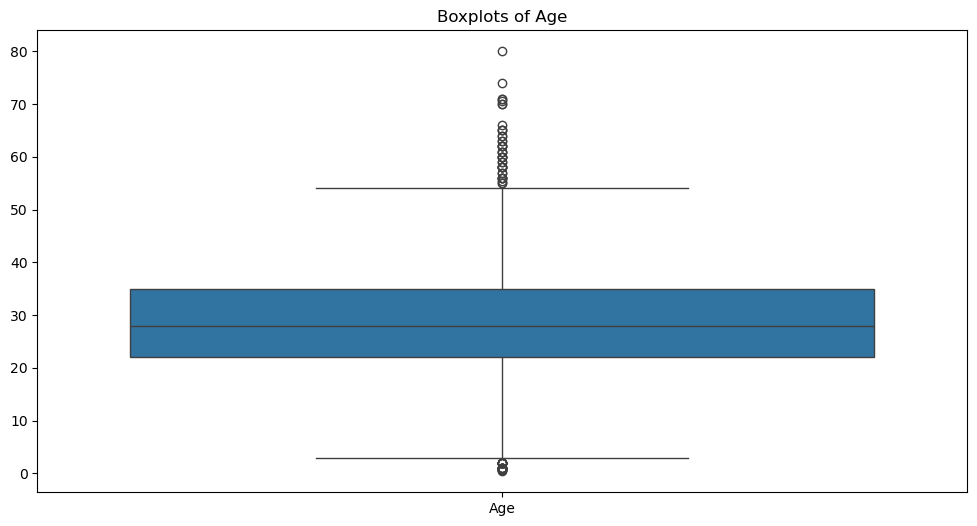

In [ ]:
plt.figure(figsize=(12,6))
sns.boxplot(data=titanic_df[['Age']])
plt.title('Boxplots of Age')
plt.show()

In [ ]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=titanic_df[['Fare']])
plt.title('Boxplots of Fare')
plt.show()

NameError: name 'plt' is not defined

##### Using IQR for 'Fare' and 'Age'

In [ ]:
Q1 = titanic_df[['Fare', 'Age']].quantile(0.25)
Q3 = titanic_df[['Fare', 'Age']].quantile(0.75)
IQR = Q3 - Q1
# Define the lower and upper bounds to identify outliers
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
# Identify outliers for 'Fare' and 'Age'
outliers_fare = (titanic_df['Fare'] < lower_bound['Fare']) | (titanic_df['Fare'] > upper_bound['Fare'])
outliers_age = (titanic_df['Age'] < lower_bound['Age']) | (titanic_df['Age'] > upper_bound['Age'])

In [ ]:
Q1

Fare     7.9104
Age     22.0000
Name: 0.25, dtype: float64

In [ ]:

# Display the number of outliers using IQR method
print("Outliers by IQR:\n")
print("Outliers in 'Fare':", outliers_fare.sum())
print("Outliers in 'Age':", outliers_age.sum())

Outliers by IQR:

Outliers in 'Fare': 116
Outliers in 'Age': 66


#####  Using Z-Score

In [ ]:
# Outliers for Fare
z_scores_fare = np.abs(stats.zscore(titanic_df['Fare']))
outliers_fare = z_scores_fare > 3
outlier_data_fare = titanic_df[outliers_fare]
print("Outliers for Fare:\n", outlier_data_fare[['Fare']])

# Outliers for Age
z_scores_age = np.abs(stats.zscore(titanic_df['Age']))
outliers_age = z_scores_age > 3
outlier_data_age = titanic_df[outliers_age]
print("Outliers for Age:\n", outlier_data_age[[ 'Age']])

NameError: name 'np' is not defined

##### Using Isolation Forest

In [ ]:
# Isolation Forest for Fare
iso_forest_fare = IsolationForest(contamination=0.05)
outliers_fare = iso_forest_fare.fit_predict(titanic_df[['Fare']])
outliers_fare = outliers_fare == -1
outlier_data_fare = titanic_df[outliers_fare]

# Isolation Forest for Age
iso_forest_age = IsolationForest(contamination=0.05)
outliers_age = iso_forest_age.fit_predict(titanic_df[['Age']])
outliers_age = outliers_age == -1
outlier_data_age = titanic_df[outliers_age]

# Print the outlier DataFrames
print("Outliers for Fare:\n", outlier_data_fare)
print("Outliers for Age:\n", outlier_data_age)

Outliers for Fare:
      PassengerId  Survived  Pclass  \
27            28         0       1   
31            32         1       1   
88            89         1       1   
118          119         0       1   
195          196         1       1   
215          216         1       1   
258          259         1       1   
268          269         1       1   
269          270         1       1   
297          298         0       1   
299          300         1       1   
305          306         1       1   
311          312         1       1   
318          319         1       1   
319          320         1       1   
325          326         1       1   
332          333         0       1   
334          335         1       1   
337          338         1       1   
341          342         1       1   
373          374         0       1   
377          378         0       1   
380          381         1       1   
390          391         1       1   
393          394         1    